# Sistema de recomendação de filmes: personalizar ou mostrar o que está em alta?

**Pergunta de negócio:** uma plataforma quer uma lista de 10 filmes na home de cada usuário. Vale a pena um modelo personalizado, ou a lista do que está em alta já resolve?

**Dados:** [MovieTweetings](https://github.com/sidooms/MovieTweetings) (Simon Dooms, licença MIT), com cerca de 920 mil avaliações de filmes publicadas no Twitter de 2013 a 2021. Cada avaliação é tratada como "assistiu ao filme" (sinal implícito).

**Roteiro**
1. Como o consumo de filmes se comporta no tempo
2. Protocolo: divisão temporal, validação e teste separados
3. Modelos: popularidade, vizinhança item × item, EASE com e sem decaimento temporal, híbrido
4. Resultados no teste e o dilema acerto × diversidade
5. Para quem a personalização ajuda
6. Recomendações e limitações

In [1]:
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")  # estilo compartilhado do repositório
from comum.estilo import COR, aplicar, br, fonte, subtitulo
from recomendacao import (K, carregar, dividir, hibrido, item_knn, metricas, pontuar_ease,
                          popularidade, top_k)

warnings.filterwarnings("ignore")
aplicar()
FONTE = "Fonte: MovieTweetings (Dooms et al., 2013) · elaboração: Cézar Bento"

av, filmes = carregar()
print(f"{br(len(av))} avaliações · {br(av.usuario.nunique())} usuários · {br(av.filme.nunique())} filmes · "
      f"{av.data.min():%m/%Y} a {av.data.max():%m/%Y}")

921.398 avaliações · 71.707 usuários · 38.013 filmes · 02/2013 a 11/2021


## 1. Filmes têm prazo de validade

Para cada avaliação, medimos quantos meses se passaram desde a primeira avaliação daquele filme na base, o que funciona como uma aproximação do lançamento.

Mediana: 3,2 meses após a primeira avaliação · nos 3 primeiros meses: 48%


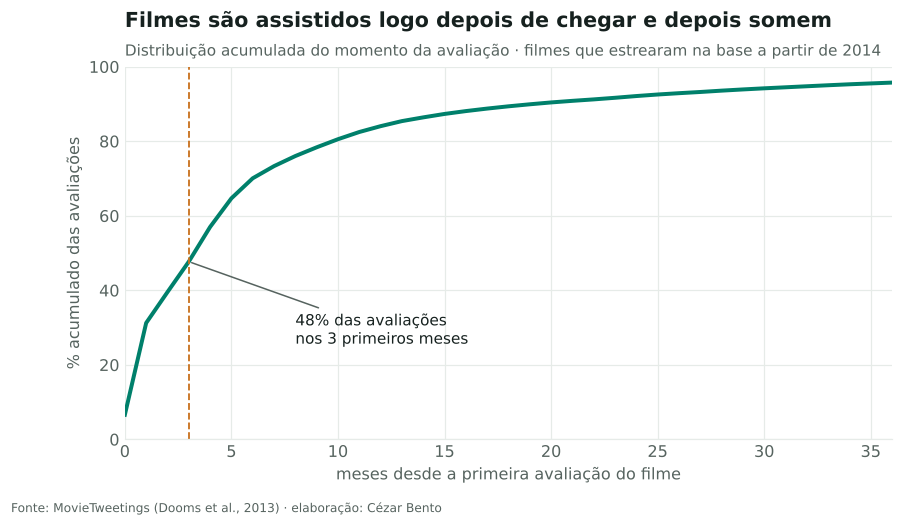

In [2]:
primeira = av.groupby("filme")["data"].transform("min")
meses = (av["data"] - primeira).dt.days / 30.4
# Só filmes que estrearam na base depois de 2014, para não confundir com o início da coleta
recentes = av[primeira >= "2014-01-01"]
meses_rec = meses[recentes.index]
grade = np.arange(0, 37)
acumulado = np.array([(meses_rec <= m).mean() for m in grade])
mediana = float(np.median(meses_rec))
p3 = (meses_rec <= 3).mean()
print(f"Mediana: {br(mediana, 1)} meses após a primeira avaliação · nos 3 primeiros meses: {br(p3 * 100)}%")

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(grade, acumulado * 100, color=COR["principal"], lw=2.6)
ax.axvline(3, color=COR["destaque"], lw=1.2, ls="--")
ax.annotate(f"{br(p3 * 100)}% das avaliações\nnos 3 primeiros meses", xy=(3, p3 * 100), xytext=(8, p3 * 100 - 22),
            fontsize=10, color=COR["texto"], arrowprops=dict(arrowstyle="-", color=COR["texto2"]))
ax.set_xlim(0, 36); ax.set_ylim(0, 100)
ax.set_xlabel("meses desde a primeira avaliação do filme"); ax.set_ylabel("% acumulado das avaliações")
ax.set_title("Filmes são assistidos logo depois de chegar e depois somem")
subtitulo(ax, "Distribuição acumulada do momento da avaliação · filmes que estrearam na base a partir de 2014")
fonte(fig, FONTE)
fig.savefig("figuras/01_vida_util.png")

**Consequência para o modelo:** o que a pessoa vai assistir no mês que vem é, em boa parte, um filme que ainda nem existia no histórico. Um modelo treinado no passado inteiro aprende gostos de filmes que já saíram de cena.

## 2. Protocolo de avaliação

- **Divisão temporal**: o modelo treina com tudo antes de uma data e é avaliado no que cada usuário assistiu nos 6 meses seguintes (só filmes inéditos para ele).
- **Validação** (corte em jan/2019) para escolher hiperparâmetros; **teste** (corte em jul/2019) só para o resultado final. Assim o número reportado não foi "escolhido" olhando o teste.
- **Catálogo**: filmes com ao menos 20 avaliações no treino; usuários com ao menos 5.
- **Métricas**: recall@10 (que fração do que o usuário assistiu estava na lista), NDCG@10 (premia acertos no topo) e cobertura (que fração do catálogo aparece em alguma lista, uma medida de diversidade).

In [3]:
val = dividir(av, "2019-01-01", "2019-07-01")
teste = dividir(av, "2019-07-01", "2020-01-01")
for nome, d in [("Validação", val), ("Teste", teste)]:
    print(f"{nome}: {br(len(d.alvo))} usuários avaliados · catálogo de {br(len(d.itens))} filmes · "
          f"{br(d.fora_catalogo * 100)}% do que foi assistido não estava no catálogo")

Validação: 3.148 usuários avaliados · catálogo de 4.619 filmes · 45% do que foi assistido não estava no catálogo
Teste: 3.178 usuários avaliados · catálogo de 4.807 filmes · 53% do que foi assistido não estava no catálogo


Quase metade do que foi assistido em cada janela são filmes que **nenhum** modelo treinado no passado pode recomendar, porque eles ainda não existiam. Esse é o teto de qualquer abordagem baseada em histórico; resolver exigiria dados do filme (gênero, elenco, lançamento) em vez de só interações.

## 3. Modelos

| Modelo | Ideia |
|---|---|
| Popularidade (histórico) | Os mais assistidos de todos os tempos, iguais para todos |
| Popularidade (60 dias) | Os mais assistidos nos últimos 60 dias, iguais para todos |
| Vizinhança item × item | "Quem viu este filme também viu…" (cosseno) |
| EASE | Modelo linear item × item com solução fechada ([Steck, 2019](https://arxiv.org/abs/1905.03375)) |
| EASE com decaimento | Igual, mas cada interação pesa `exp(-idade/τ)`: o gosto recente conta mais |
| Híbrido | Mistura α · popularidade recente + (1 − α) · EASE com decaimento |

**Escolha de hiperparâmetros na validação**: meia-vida do decaimento (τ) e regularização (λ) do EASE.

In [4]:
busca = []
for tau in [30, 60, 90, 180, None]:
    for lam in [300, 1000, 3000]:
        m, _ = metricas(val, top_k(val, pontuar_ease(val, lam, tau)))
        busca.append({"tau": tau if tau else "sem decaimento", "lambda": lam, **m})
busca = pd.DataFrame(busca)
print(busca.round(4).to_string(index=False))
melhor = busca.loc[busca.recall.idxmax()]
TAU, LAM = int(melhor["tau"]), int(melhor["lambda"])
print(f"\nEscolhido: τ = {TAU} dias, λ = {LAM}")

           tau  lambda  recall   ndcg  cobertura
            30     300  0.0809 0.0781     0.2293
            30    1000  0.0825 0.0800     0.2245
            30    3000  0.0837 0.0807     0.2208
            60     300  0.0912 0.0858     0.2068
            60    1000  0.0945 0.0880     0.1946
            60    3000  0.0955 0.0887     0.1875
            90     300  0.0902 0.0845     0.1838
            90    1000  0.0928 0.0860     0.1576
            90    3000  0.0960 0.0878     0.1409
           180     300  0.0806 0.0721     0.1284
           180    1000  0.0824 0.0714     0.0866
           180    3000  0.0806 0.0699     0.0630
sem decaimento     300  0.0186 0.0156     0.1912
sem decaimento    1000  0.0166 0.0140     0.1518
sem decaimento    3000  0.0151 0.0126     0.1167

Escolhido: τ = 90 dias, λ = 3000


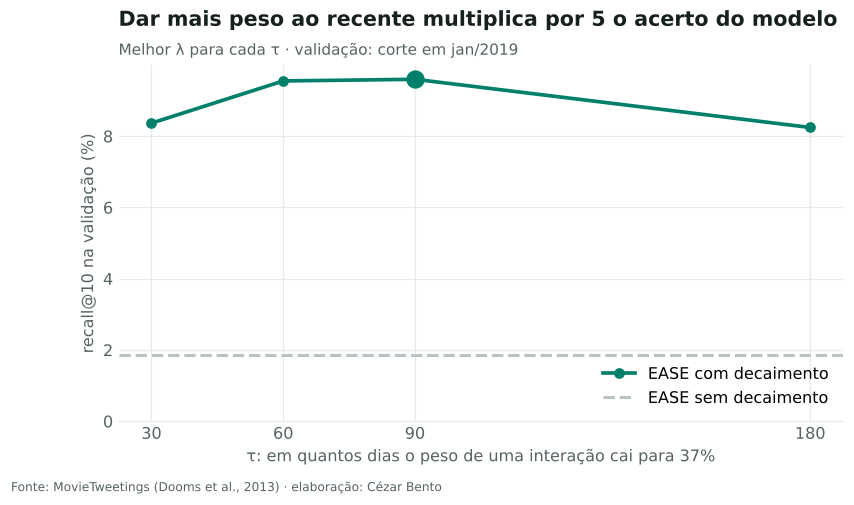

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
com = busca[busca.tau != "sem decaimento"].groupby("tau").recall.max()
sem = busca[busca.tau == "sem decaimento"].recall.max()
ax.plot(com.index.astype(int), com.values * 100, color=COR["principal"], marker="o", lw=2.4, label="EASE com decaimento")
ax.axhline(sem * 100, color=COR["contexto"], lw=2, ls="--", label="EASE sem decaimento")
ax.plot(TAU, com.loc[TAU] * 100, marker="o", ms=11, color=COR["principal"])
ax.set_xticks(com.index.astype(int)); ax.set_xlabel("τ: em quantos dias o peso de uma interação cai para 37%")
ax.set_ylabel("recall@10 na validação (%)"); ax.set_ylim(0, None); ax.legend(loc="lower right")
ax.set_title(f"Dar mais peso ao recente multiplica por {br(com.max() / sem)} o acerto do modelo")
subtitulo(ax, "Melhor λ para cada τ · validação: corte em jan/2019")
fonte(fig, FONTE)
fig.savefig("figuras/02_decaimento.png")

## 4. Resultados no teste

In [6]:
pop60 = popularidade(teste, 60)
ease_dec = pontuar_ease(teste, LAM, TAU)
pontuacoes = {
    "Popularidade (histórico)": popularidade(teste),
    "Vizinhança item × item": item_knn(teste),
    "EASE": pontuar_ease(teste, LAM),
    "EASE com decaimento": ease_dec,
    "Híbrido (α = 0,25)": hibrido(ease_dec, pop60, 0.25),
    "Popularidade (60 dias)": pop60,
}
resultados, recall_usuario, listas = {}, {}, {}
for nome, S in pontuacoes.items():
    listas[nome] = top_k(teste, S)
    resultados[nome], recall_usuario[nome] = metricas(teste, listas[nome])
res = pd.DataFrame(resultados).T
print((res * 100).round(2).rename(columns={"recall": "recall@10 %", "ndcg": "NDCG@10 %", "cobertura": "cobertura %"}).to_string())

# A diferença de recall é real ou ruído? Bootstrap pareado sobre usuários (mesmos usuários nos dois modelos)
rng = np.random.default_rng(0)
base = recall_usuario["Popularidade (60 dias)"]
print()
for nome in ["EASE com decaimento", "Híbrido (α = 0,25)"]:
    dif = recall_usuario[nome] - base
    amostras = [dif[rng.integers(0, len(dif), len(dif))].mean() for _ in range(2000)]
    lo, hi = np.percentile(amostras, [2.5, 97.5])
    print(f"{nome} − popularidade (60 dias): {dif.mean() * 100:+.2f} p.p. (IC 95%: {lo * 100:+.2f} a {hi * 100:+.2f})")

                          recall@10 %  NDCG@10 %  cobertura %
Popularidade (histórico)         0.57       0.47         1.54
Vizinhança item × item           1.00       0.86        13.73
EASE                             1.53       1.29        12.48
EASE com decaimento              6.00       5.71        14.92
Híbrido (α = 0,25)               6.29       5.87        10.19
Popularidade (60 dias)           5.94       5.49         0.62

EASE com decaimento − popularidade (60 dias): +0.06 p.p. (IC 95%: -0.25 a +0.38)
Híbrido (α = 0,25) − popularidade (60 dias): +0.35 p.p. (IC 95%: +0.05 a +0.63)


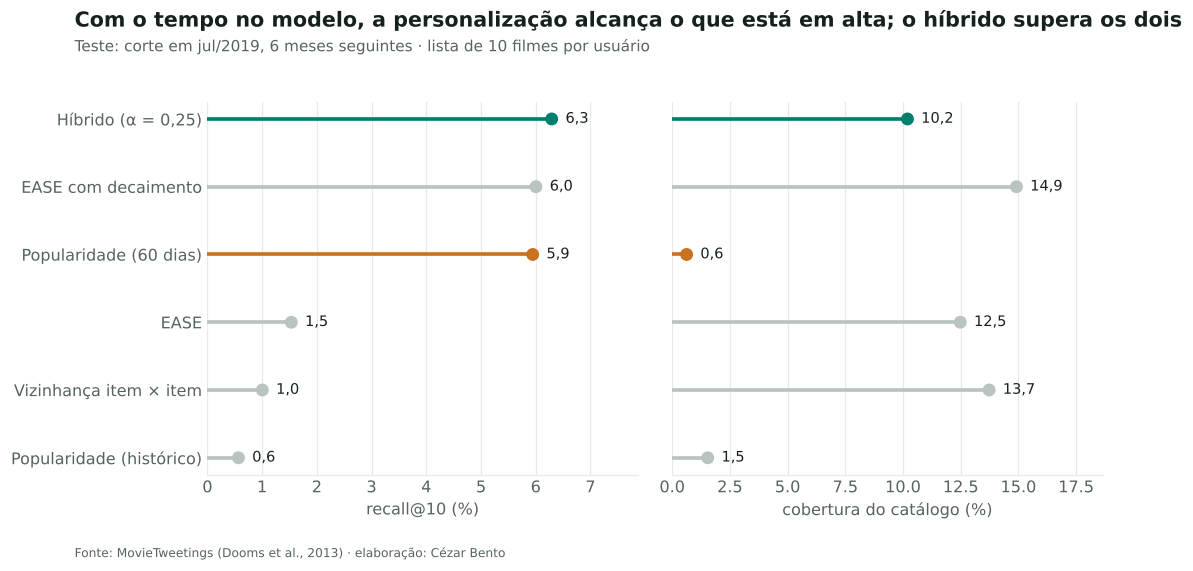

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), sharey=True, gridspec_kw={"wspace": 0.08})
ordem = res.sort_values("recall").index
y = np.arange(len(ordem))
for ax, col, rotulo in [(axes[0], "recall", "recall@10 (%)"), (axes[1], "cobertura", "cobertura do catálogo (%)")]:
    vals = res.loc[ordem, col] * 100
    cores = [COR["destaque"] if n == "Popularidade (60 dias)" else COR["principal"] if n == "Híbrido (α = 0,25)"
             else COR["contexto"] for n in ordem]
    ax.hlines(y, 0, vals, color=cores, lw=2.4)
    ax.scatter(vals, y, color=cores, s=55, zorder=3)
    for yi, v in zip(y, vals):
        ax.text(v + vals.max() * 0.04, yi, br(v, 1), va="center", fontsize=9.5, color=COR["texto"])
    ax.set_xlim(0, vals.max() * 1.25); ax.set_xlabel(rotulo); ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, ordem)
fig.suptitle("Com o tempo no modelo, a personalização alcança o que está em alta; o híbrido supera os dois",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold", color=COR["texto"], y=1.07)
fig.text(0.01, 0.985, "Teste: corte em jul/2019, 6 meses seguintes · lista de 10 filmes por usuário",
         fontsize=10, color=COR["texto2"])
fonte(fig, FONTE, y=-0.04)
fig.savefig("figuras/03_modelos.png")

**Leitura:**
- Sem considerar o tempo, os modelos personalizados (vizinhança e EASE) acertam de 4 a 6 vezes menos que a lista do que está em alta.
- Com decaimento temporal, o EASE **empata** com a popularidade recente (a diferença não é estatisticamente distinta de zero), mas cada usuário recebe uma lista própria.
- O **híbrido** é o único que supera a popularidade com confiança: cerca de +0,3 ponto percentual de recall, com intervalo de 95% acima de zero.

### O dilema acerto × diversidade

A popularidade recente mostra a **mesma** lista para todo mundo e usa menos de 1% do catálogo. Variar o peso α do híbrido desenha a fronteira entre acerto e cobertura.

In [8]:
fronteira = []
for alfa in [0, 0.1, 0.25, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]:
    m, _ = metricas(teste, top_k(teste, hibrido(ease_dec, pop60, alfa)))
    fronteira.append({"alfa": alfa, **m})
fronteira = pd.DataFrame(fronteira)
print(fronteira.round(4).to_string(index=False))
ref = fronteira.set_index("alfa")
perda = 1 - ref.loc[0.25, "recall"] / ref.loc[1.0, "recall"]
ganho = ref.loc[0.25, "cobertura"] / ref.loc[1.0, "cobertura"]
print(f"\nα = 0,25 contra só popularidade: recall {-perda * 100:+.0f}% e {br(ganho)}× mais cobertura")

 alfa  recall   ndcg  cobertura
 0.00  0.0600 0.0571     0.1492
 0.10  0.0621 0.0583     0.1250
 0.25  0.0629 0.0587     0.1019
 0.40  0.0635 0.0592     0.0755
 0.50  0.0647 0.0602     0.0499
 0.60  0.0649 0.0604     0.0270
 0.70  0.0639 0.0600     0.0129
 0.80  0.0622 0.0586     0.0067
 1.00  0.0594 0.0549     0.0062

α = 0,25 contra só popularidade: recall +6% e 16× mais cobertura


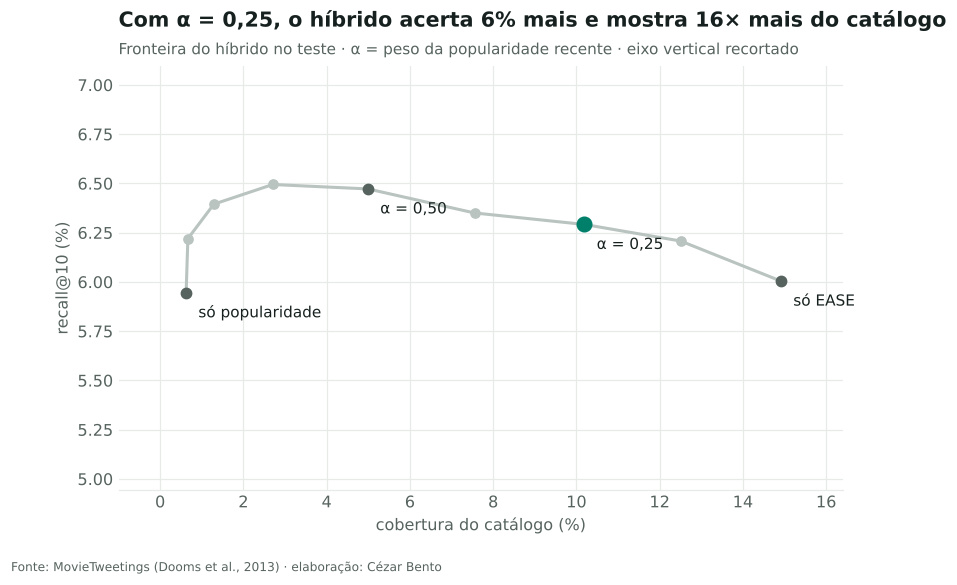

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.plot(fronteira.cobertura * 100, fronteira.recall * 100, color=COR["contexto"], lw=2, marker="o", zorder=2)
for _, r in fronteira.iterrows():
    if r.alfa in (0, 0.25, 0.5, 1.0):
        destaque = r.alfa == 0.25
        ax.scatter(r.cobertura * 100, r.recall * 100, s=90 if destaque else 45, zorder=3,
                   color=COR["principal"] if destaque else COR["texto2"])
        texto = {0: "só EASE", 1.0: "só popularidade"}.get(r.alfa, f"α = {br(r.alfa, 2)}")
        ax.annotate(texto, (r.cobertura * 100, r.recall * 100), xytext=(8, -16),
                    textcoords="offset points", fontsize=10, color=COR["texto"])
ax.set_xlabel("cobertura do catálogo (%)"); ax.set_ylabel("recall@10 (%)")
ax.set_ylim(fronteira.recall.min() * 100 - 1, fronteira.recall.max() * 100 + 0.6); ax.set_xlim(-1, fronteira.cobertura.max() * 110)
ax.set_title(f"Com α = 0,25, o híbrido acerta {br(-perda * 100)}% mais e mostra {br(ganho)}× mais do catálogo")
subtitulo(ax, "Fronteira do híbrido no teste · α = peso da popularidade recente · eixo vertical recortado")
fonte(fig, FONTE)
fig.savefig("figuras/04_fronteira.png")

**Sobre a escolha de α:** α é uma decisão de negócio (quanto de diversidade se quer), não um hiperparâmetro a otimizar no teste. O valor 0,25 foi fixado antes de olhar o teste. Na validação, ele custava cerca de 9% de recall em relação à popularidade; no teste, ganhou 6%. A conclusão estável entre os dois períodos é que **a diferença de acerto é pequena e o ganho de cobertura é grande**.

## 5. Para quem a personalização ajuda?

             Popularidade (60 dias)  EASE com decaimento  Híbrido (α = 0,25)  usuários
faixa                                                                                 
5–10                           4.86                 4.62                4.92       681
11–30                          5.02                 5.03                5.29       970
31–100                         5.82                 5.91                6.16       871
mais de 100                    9.26                 9.81               10.20       589


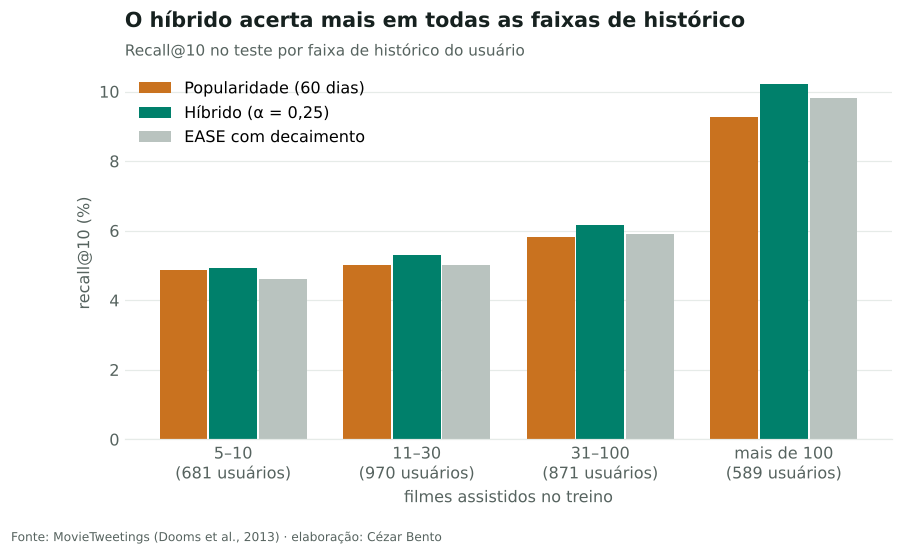

In [10]:
historico = np.asarray(teste.X[teste.linhas].sum(axis=1)).ravel()
faixas = pd.cut(historico, [4, 10, 30, 100, np.inf], labels=["5–10", "11–30", "31–100", "mais de 100"])
comp = pd.DataFrame({"faixa": faixas,
                     "Popularidade (60 dias)": recall_usuario["Popularidade (60 dias)"],
                     "EASE com decaimento": recall_usuario["EASE com decaimento"],
                     "Híbrido (α = 0,25)": recall_usuario["Híbrido (α = 0,25)"]})
por_faixa = comp.groupby("faixa").mean() * 100
por_faixa["usuários"] = comp.groupby("faixa").size()
print(por_faixa.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(por_faixa))
for desloc, (nome, cor) in zip([-0.27, 0, 0.27], [("Popularidade (60 dias)", COR["destaque"]),
                                                  ("Híbrido (α = 0,25)", COR["principal"]),
                                                  ("EASE com decaimento", COR["contexto"])]):
    ax.bar(x + desloc, por_faixa[nome], width=0.26, color=cor, label=nome)
ax.set_xticks(x, [f"{f}\n({br(n)} usuários)" for f, n in zip(por_faixa.index, por_faixa["usuários"])])
ax.set_xlabel("filmes assistidos no treino"); ax.set_ylabel("recall@10 (%)"); ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
ax.set_title("O híbrido acerta mais em todas as faixas de histórico")
subtitulo(ax, "Recall@10 no teste por faixa de histórico do usuário")
fonte(fig, FONTE, y=-0.08)
fig.savefig("figuras/05_por_historico.png")

### Exemplo: a lista de um usuário

In [11]:
# Usuário com histórico médio (perto de 40 filmes) e ao menos 3 filmes no teste, para ver as listas lado a lado
n_teste = np.array([len(teste.alvo[u]) for u in teste.alvo.index])
idx = int(np.argmin(np.abs(historico - 40) + 1000 * (n_teste < 3)))
usuario = teste.alvo.index[idx]
vistos = teste.treino[teste.treino.usuario == usuario].sort_values("data").filme.tail(5)
print("Últimos filmes assistidos no treino:")
for f in vistos:
    print("  ·", filmes.loc[f, "titulo"])
tabela = pd.DataFrame({nome: [filmes.loc[f, "titulo"] for f in teste.itens[listas[nome][idx]]]
                       for nome in ["Popularidade (60 dias)", "Híbrido (α = 0,25)", "EASE com decaimento"]},
                      index=range(1, K + 1))
print()
print(tabela.to_string())
print("\nAssistiu de fato no teste:", "; ".join(filmes.loc[f, "titulo"] for f in list(teste.alvo[usuario])[:8]))

Últimos filmes assistidos no treino:
  · The Imitation Game (2014)
  · Back to the Future (1985)
  · Toy Story 3 (2010)
  · Us (2019)
  · Murder Mystery (2019)

                               Popularidade (60 dias)                        Híbrido (α = 0,25)                       EASE com decaimento
1            John Wick: Chapter 3 - Parabellum (2019)                  Avengers: Endgame (2019)                  Avengers: Endgame (2019)
2                            Avengers: Endgame (2019)                            Shazam! (2019)                            Shazam! (2019)
3                                      Aladdin (2019)  John Wick: Chapter 3 - Parabellum (2019)                        Toy Story 4 (2019)
4                                  Toy Story 4 (2019)                        Toy Story 4 (2019)  John Wick: Chapter 3 - Parabellum (2019)
5                   Pokémon: Detective Pikachu (2019)                            Aladdin (2019)                            Aladdin (2019)
6          

**Leitura:** as três listas são parecidas no topo (o que está em alta domina) e se diferenciam do 5º lugar em diante, onde o histórico do usuário entra. Neste caso nenhuma acertou: ele foi atrás de clássicos e de lançamentos do fim do ano, que ainda não existiam no corte. É o retrato do teto discutido na seção 2.

## 6. Recomendações

1. **Em produção, usar o híbrido com α baixo (0,25)**: acerta um pouco mais que a lista do que está em alta e mostra a cada pessoa uma lista própria, com cerca de 16 vezes mais do catálogo. A diversidade importa para o negócio (exposição de títulos de catálogo, menos dependência de lançamentos) e não aparece no recall.
2. **O tempo é a variável mais importante**: o decaimento multiplica por 5 o acerto do modelo personalizado. Em consumo com "prazo de validade", o modelo precisa ser retreinado com frequência (diária ou semanal).
3. **Metade do consumo é de filmes novos**: o próximo ganho real vem de um modelo que use atributos do filme (gênero, elenco, data de estreia) para recomendar lançamentos sem histórico.
4. **Validar online**: recall offline mede o que a pessoa assistiu *sem* a recomendação. O efeito real (cliques, horas assistidas) só aparece num teste A/B.

## Limitações

- Avaliações publicadas no Twitter são uma amostra de quem gosta de tuitar sobre filmes, não do público geral.
- O sinal é implícito: avaliar um filme com nota 2 conta como "assistiu", igual a uma nota 10.
- Recall offline subestima modelos que recomendam coisas novas ao usuário que ele não teria achado sozinho.